# Demostración de la normalización de `\limits`: SAN vs. PosFormer

Este notebook muestra el **antes y después** de la normalización conservadora definida para comparar las anotaciones del test CROHME 2014 utilizado por ambos modelos.

| Modelo | Ruta de imágenes | Anotaciones |
|---|---|---|
| SAN (Modelo1) | `data/Modelo1/2014/14_test_images/*.bmp` | `test_caption.txt` |
| PosFormer (Modelo2) | `data/Modelo2/2014/img/*.bmp` | `caption.txt` |

Para cada muestra seleccionada se presentan:

1. la imagen correspondiente a SAN;
2. la imagen correspondiente a PosFormer;
3. ambos *ground truth* originales;
4. ambos *ground truth* después de retirar únicamente el token exacto `\limits`;
5. el estado de igualdad antes y después de la normalización.

El notebook es demostrativo: no modifica los datasets ni sustituye sus anotaciones originales.

## Criterio metodológico

La normalización se aplica únicamente para la comparación y el cálculo de métricas. Se conservan tanto la comparación estricta como la comparación normalizada.

La única transformación automática es:

```text
eliminar token si token == \limits
```

No se corrigen comas, llaves, subíndices ni diferencias como `\pi` frente a `\Pi`. Los casos que sigan siendo distintos se muestran por separado para revisión manual.

## 1. Importaciones y configuración

`MAX_CASOS_DEMOSTRACION` controla cuántos ejemplos se dibujan automáticamente. Puede asignarse `None` para visualizar todos los casos explicados únicamente por `\limits`.

In [8]:
# Importaciones para rutas, hashes, tablas, imágenes y visualización.
from pathlib import Path
import hashlib
import math
import re
import textwrap

import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt

# Configuración reproducible de la demostración.
MAX_CASOS_DEMOSTRACION = 12
COLUMNAS_POR_FIGURA = 2
ANCHO_TEXTO = 78

pd.set_option("display.max_colwidth", 180)
pd.set_option("display.max_rows", 100)

## 2. Localización del repositorio y rutas

La raíz se localiza comprobando la existencia de ambos archivos de anotaciones. Así se evita depender del directorio desde el que se abra Jupyter.

In [9]:
# Localiza la raíz sin asumir que el notebook se ejecuta desde una carpeta concreta.
def localizar_raiz(inicio=None):
    inicio = Path.cwd() if inicio is None else Path(inicio)
    inicio = inicio.resolve()
    for raiz in [inicio, *inicio.parents]:
        requeridos = [
            raiz / "data" / "Modelo1" / "2014" / "test_caption.txt",
            raiz / "data" / "Modelo2" / "2014" / "caption.txt",
        ]
        if all(ruta.is_file() for ruta in requeridos):
            return raiz
    raise FileNotFoundError(
        "No se encontraron los tests 2014 de SAN y PosFormer desde el directorio actual."
    )

RAIZ = localizar_raiz()

SAN_DIR = RAIZ / "data" / "Modelo1" / "2014"
POSFORMER_DIR = RAIZ / "data" / "Modelo2" / "2014"

SAN_CAPTION = SAN_DIR / "test_caption.txt"
POSFORMER_CAPTION = POSFORMER_DIR / "caption.txt"

SAN_IMG_DIR = SAN_DIR / "14_test_images"
POSFORMER_IMG_DIR = POSFORMER_DIR / "img"

print(f"Raíz: {RAIZ}")
print(f"SAN: {SAN_DIR.relative_to(RAIZ)}")
print(f"PosFormer: {POSFORMER_DIR.relative_to(RAIZ)}")

Raíz: /mnt/c/Users/novac/Documents/Unidad/Documentos/IPN/Trabajo_terminal/Programas
SAN: data/Modelo1/2014
PosFormer: data/Modelo2/2014


## 3. Lectura y alineación por identificador

Los archivos de anotaciones tienen órdenes diferentes. Por ello, las muestras se alinean exclusivamente por ID. En SAN se retira solo el sufijo técnico `_0` del nombre del BMP para recuperar el ID canónico.

In [10]:
# Lee cada caption conservando el ground truth original y la posición de la línea.
def leer_caption(ruta, nombre):
    registros = []
    with ruta.open("r", encoding="utf-8-sig") as archivo:
        for numero_linea, linea_cruda in enumerate(archivo, start=1):
            linea = linea_cruda.rstrip("\r\n")
            if not linea.strip():
                continue
            if "\t" not in linea:
                raise ValueError(
                    f"{ruta.name}, línea {numero_linea}: falta el separador de tabulación."
                )
            identificador, latex = linea.split("\t", maxsplit=1)
            registros.append(
                {
                    "id": identificador.strip(),
                    f"ground_truth_{nombre}": latex.strip(),
                    f"posicion_{nombre}": numero_linea - 1,
                }
            )

    tabla = pd.DataFrame(registros)
    if tabla["id"].duplicated().any():
        ids = tabla.loc[tabla["id"].duplicated(keep=False), "id"].tolist()
        raise ValueError(f"IDs duplicados en {nombre}: {ids[:10]}")
    return tabla

caption_san = leer_caption(SAN_CAPTION, "san")
caption_posformer = leer_caption(POSFORMER_CAPTION, "posformer")

# Construye mapas ID -> imagen usando la convención real de cada modelo.
imagenes_san = sorted(SAN_IMG_DIR.glob("*.bmp"))
imagenes_posformer = sorted(POSFORMER_IMG_DIR.glob("*.bmp"))

mapa_imagen_san = {
    re.sub(r"_0$", "", ruta.stem): ruta
    for ruta in imagenes_san
}
mapa_imagen_posformer = {
    ruta.stem: ruta
    for ruta in imagenes_posformer
}

# Alinea los ground truth por ID y verifica que ambas imágenes estén disponibles.
comparacion = caption_san.merge(
    caption_posformer,
    on="id",
    how="outer",
    validate="one_to_one",
    indicator=True,
)
comparacion["ruta_imagen_san"] = comparacion["id"].map(mapa_imagen_san)
comparacion["ruta_imagen_posformer"] = comparacion["id"].map(mapa_imagen_posformer)

problemas = pd.Series(
    {
        "filas alineadas": len(comparacion),
        "solo en un caption": int(comparacion["_merge"].ne("both").sum()),
        "sin imagen SAN": int(comparacion["ruta_imagen_san"].isna().sum()),
        "sin imagen PosFormer": int(comparacion["ruta_imagen_posformer"].isna().sum()),
    },
    name="cantidad",
)
display(problemas.to_frame())

if problemas.drop("filas alineadas").sum() != 0:
    raise ValueError("La correspondencia no es completa; revise los inventarios antes de continuar.")

,cantidad
filas alineadas,986
solo en un caption,0
sin imagen SAN,0
sin imagen PosFormer,0


## 4. Regla de normalización

La función divide por espacios, elimina únicamente tokens exactamente iguales a `\limits` y vuelve a unir la secuencia. Las columnas originales se conservan sin cambios.

In [11]:
# Normaliza solo el token exacto \limits; no aplica reemplazos de subcadenas.
def normalizar_limits(secuencia):
    tokens = str(secuencia).split()
    return " ".join(token for token in tokens if token != r"\limits")

# Conserva los originales y crea columnas nuevas para la comparación normalizada.
comparacion["ground_truth_san_normalizado"] = comparacion[
    "ground_truth_san"
].map(normalizar_limits)
comparacion["ground_truth_posformer_normalizado"] = comparacion[
    "ground_truth_posformer"
].map(normalizar_limits)

comparacion["iguales_antes"] = (
    comparacion["ground_truth_san"] == comparacion["ground_truth_posformer"]
)
comparacion["iguales_despues"] = (
    comparacion["ground_truth_san_normalizado"]
    == comparacion["ground_truth_posformer_normalizado"]
)
comparacion["san_tiene_limits"] = comparacion["ground_truth_san"].map(
    lambda texto: r"\limits" in texto.split()
)
comparacion["posformer_tiene_limits"] = comparacion["ground_truth_posformer"].map(
    lambda texto: r"\limits" in texto.split()
)

# Clasifica cada par sin ocultar las diferencias que la regla no resuelve.
comparacion["categoria"] = np.select(
    [
        comparacion["iguales_antes"],
        (~comparacion["iguales_antes"]) & comparacion["iguales_despues"],
    ],
    [
        "iguales originalmente",
        r"diferencia explicada solo por \limits",
    ],
    default="diferencia no resuelta por la normalización",
)

display(comparacion["categoria"].value_counts().rename("cantidad").to_frame())

,cantidad
iguales originalmente,901
diferencia explicada solo por \limits,79
diferencia no resuelta por la normalización,6


## 5. Verificación de las imágenes

El objetivo es confirmar que la demostración compara la misma entrada visual. Una huella SHA-256 igual significa que los dos BMP son idénticos byte a byte. Esta verificación no altera las imágenes.

In [12]:
# Calcula SHA-256 por bloques para no cargar el archivo completo innecesariamente.
def sha256_archivo(ruta, tamano_bloque=1024 * 1024):
    digest = hashlib.sha256()
    with Path(ruta).open("rb") as archivo:
        while True:
            bloque = archivo.read(tamano_bloque)
            if not bloque:
                break
            digest.update(bloque)
    return digest.hexdigest()

comparacion["sha256_san"] = comparacion["ruta_imagen_san"].map(sha256_archivo)
comparacion["sha256_posformer"] = comparacion[
    "ruta_imagen_posformer"
].map(sha256_archivo)
comparacion["imagenes_identicas"] = (
    comparacion["sha256_san"] == comparacion["sha256_posformer"]
)

resumen_imagenes = pd.Series(
    {
        "pares comparados": len(comparacion),
        "imágenes idénticas byte a byte": int(comparacion["imagenes_identicas"].sum()),
        "imágenes con hash diferente": int((~comparacion["imagenes_identicas"]).sum()),
    },
    name="cantidad",
)
display(resumen_imagenes.to_frame())

,cantidad
pares comparados,986
imágenes idénticas byte a byte,986
imágenes con hash diferente,0


## 6. Resumen antes y después

Esta tabla cuantifica cuántos pares cambian de “diferentes” a “iguales” al retirar únicamente `\limits`. La comparación estricta permanece disponible en la columna “antes”.

In [13]:
# Resume el efecto de la regla sin convertirlo todavía en una métrica de reconocimiento.
resumen_normalizacion = pd.Series(
    {
        "pares totales": len(comparacion),
        "ground truth iguales antes": int(comparacion["iguales_antes"].sum()),
        "ground truth diferentes antes": int((~comparacion["iguales_antes"]).sum()),
        "ground truth iguales después": int(comparacion["iguales_despues"].sum()),
        "ground truth diferentes después": int((~comparacion["iguales_despues"]).sum()),
        "casos resueltos solo por quitar limits": int(
            ((~comparacion["iguales_antes"]) & comparacion["iguales_despues"]).sum()
        ),
    },
    name="cantidad",
)
display(resumen_normalizacion.to_frame())

# Tabla trazable con el antes y después de todos los pares que cambia la regla.
casos_solo_limits = comparacion.loc[
    (~comparacion["iguales_antes"]) & comparacion["iguales_despues"]
].copy().sort_values("id")

# La tabla visible se limita a las columnas de interés, pero cada fila conserva
# las rutas y banderas necesarias para las visualizaciones posteriores.
display(
    casos_solo_limits[
        [
            "id",
            "ground_truth_san",
            "ground_truth_posformer",
            "ground_truth_san_normalizado",
            "ground_truth_posformer_normalizado",
            "imagenes_identicas",
        ]
    ]
)

,cantidad
pares totales,986
ground truth iguales antes,901
ground truth diferentes antes,85
ground truth iguales después,980
ground truth diferentes después,6
casos resueltos solo por quitar limits,79


,id,ground_truth_san,ground_truth_posformer,ground_truth_san_normalizado,ground_truth_posformer_normalizado,imagenes_identicas
20,18_em_5,\int g = \lim _ { n \rightarrow \infty } \int g _ { n },\int g = \lim \limits _ { n \rightarrow \infty } \int g _ { n },\int g = \lim _ { n \rightarrow \infty } \int g _ { n },\int g = \lim _ { n \rightarrow \infty } \int g _ { n },True
59,23_em_59,\sum _ { r = 1 } ^ { n } a r ^ { b } = a \sum _ { r = 1 } ^ { n } r ^ { b },\sum \limits _ { r = 1 } ^ { n } a r ^ { b } = a \sum \limits _ { r = 1 } ^ { n } r ^ { b },\sum _ { r = 1 } ^ { n } a r ^ { b } = a \sum _ { r = 1 } ^ { n } r ^ { b },\sum _ { r = 1 } ^ { n } a r ^ { b } = a \sum _ { r = 1 } ^ { n } r ^ { b },True
72,23_em_72,\sum _ { i = 1 } ^ { n } x _ { n } = \sum _ { i = 1 } ^ { n } y _ { n },\sum \limits _ { i = 1 } ^ { n } x _ { n } = \sum \limits _ { i = 1 } ^ { n } y _ { n },\sum _ { i = 1 } ^ { n } x _ { n } = \sum _ { i = 1 } ^ { n } y _ { n },\sum _ { i = 1 } ^ { n } x _ { n } = \sum _ { i = 1 } ^ { n } y _ { n },True
76,26_em_77,x ^ { i } e _ { i } = \sum _ { i } x ^ { i } e _ { i },x ^ { i } e _ { i } = \sum \limits _ { i } x ^ { i } e _ { i },x ^ { i } e _ { i } = \sum _ { i } x ^ { i } e _ { i },x ^ { i } e _ { i } = \sum _ { i } x ^ { i } e _ { i },True
83,26_em_84,S _ { \infty } = \lim _ { n \rightarrow \infty } \frac { a ( 1 - r ^ { n } ) } { 1 - r } = \frac { a } { 1 - r },S _ { \infty } = \lim \limits _ { n \rightarrow \infty } \frac { a ( 1 - r ^ { n } ) } { 1 - r } = \frac { a } { 1 - r },S _ { \infty } = \lim _ { n \rightarrow \infty } \frac { a ( 1 - r ^ { n } ) } { 1 - r } = \frac { a } { 1 - r },S _ { \infty } = \lim _ { n \rightarrow \infty } \frac { a ( 1 - r ^ { n } ) } { 1 - r } = \frac { a } { 1 - r },True
101,27_em_102,\lim _ { a \rightarrow \infty } f ( a ),\lim \limits _ { a \rightarrow \infty } f ( a ),\lim _ { a \rightarrow \infty } f ( a ),\lim _ { a \rightarrow \infty } f ( a ),True
125,28_em_126,\frac { \sum _ { k = 1 } ^ { N } k ^ { 2 } } { a },\frac { \sum \limits _ { k = 1 } ^ { N } k ^ { 2 } } { a },\frac { \sum _ { k = 1 } ^ { N } k ^ { 2 } } { a },\frac { \sum _ { k = 1 } ^ { N } k ^ { 2 } } { a },True
143,28_em_144,\sum _ { i } k _ { i },\sum \limits _ { i } k _ { i },\sum _ { i } k _ { i },\sum _ { i } k _ { i },True
160,29_em_161,f ( z _ { 0 } ) = \lim _ { z \rightarrow z _ { 0 } } f ( z ),f ( z _ { 0 } ) = \lim \limits _ { z \rightarrow z _ { 0 } } f ( z ),f ( z _ { 0 } ) = \lim _ { z \rightarrow z _ { 0 } } f ( z ),f ( z _ { 0 } ) = \lim _ { z \rightarrow z _ { 0 } } f ( z ),True
169,29_em_171,\lim _ { t \rightarrow c } a _ { 1 } ( t ) = a _ { 1 },\lim \limits _ { t \rightarrow c } a _ { 1 } ( t ) = a _ { 1 },\lim _ { t \rightarrow c } a _ { 1 } ( t ) = a _ { 1 },\lim _ { t \rightarrow c } a _ { 1 } ( t ) = a _ { 1 },True


## 7. Visualización comparativa

Cada panel presenta las dos imágenes en la parte superior. Debajo se muestran los *ground truth* originales y normalizados como texto literal, para evitar que el renderizado de LaTeX oculte diferencias de tokens.

Por defecto se muestran los primeros casos ordenados por ID. Para revisar los 79 casos observados en el EDA, cambie `MAX_CASOS_DEMOSTRACION = None` al inicio del notebook.

Se mostrarán 12 de 79 casos explicados solo por \limits.


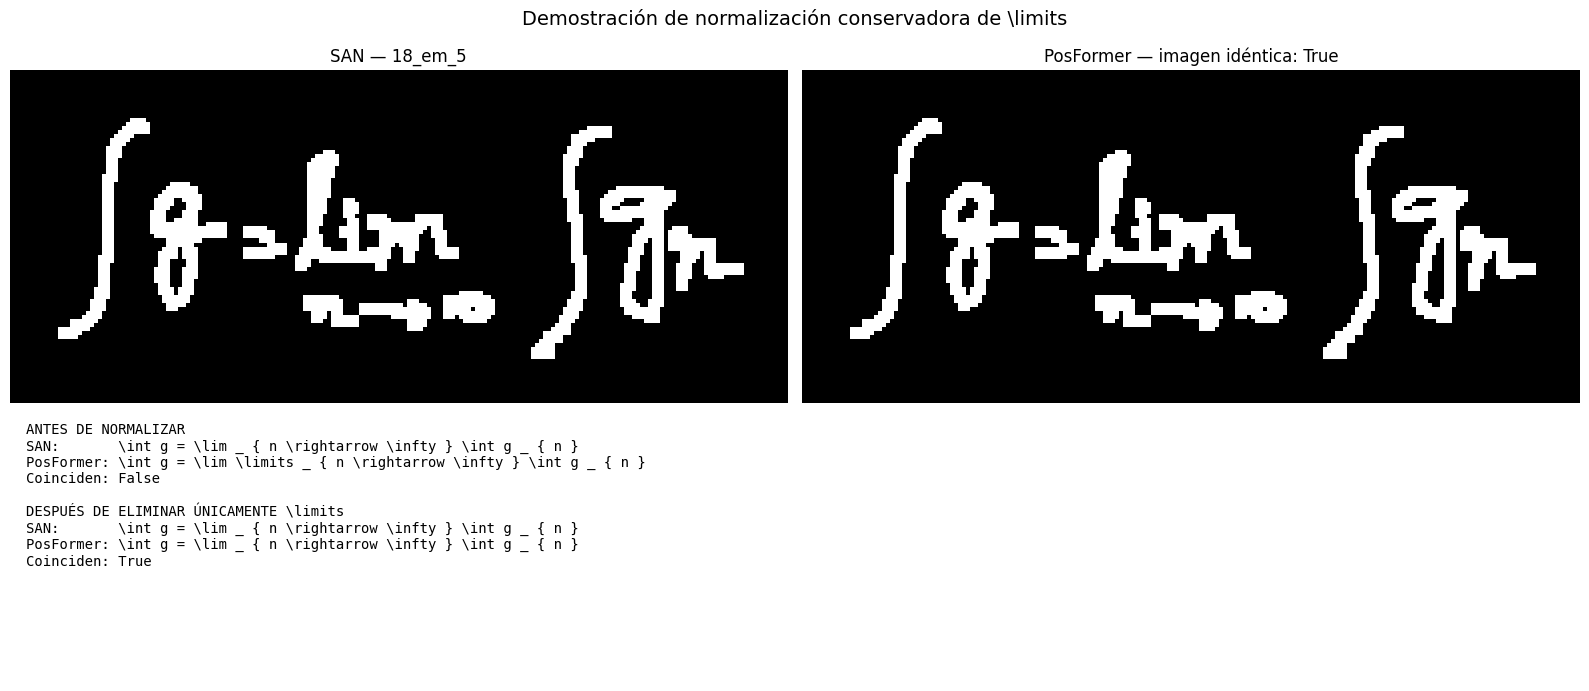

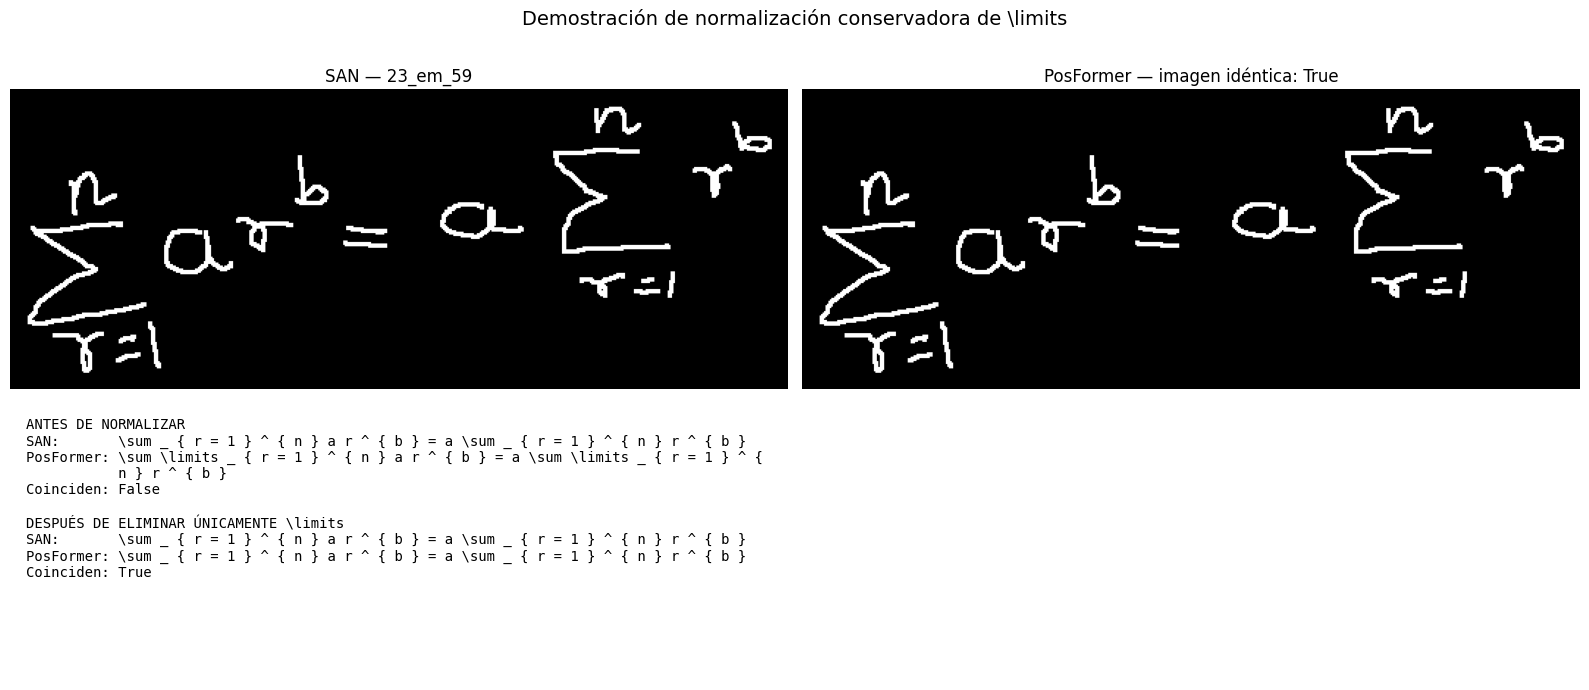

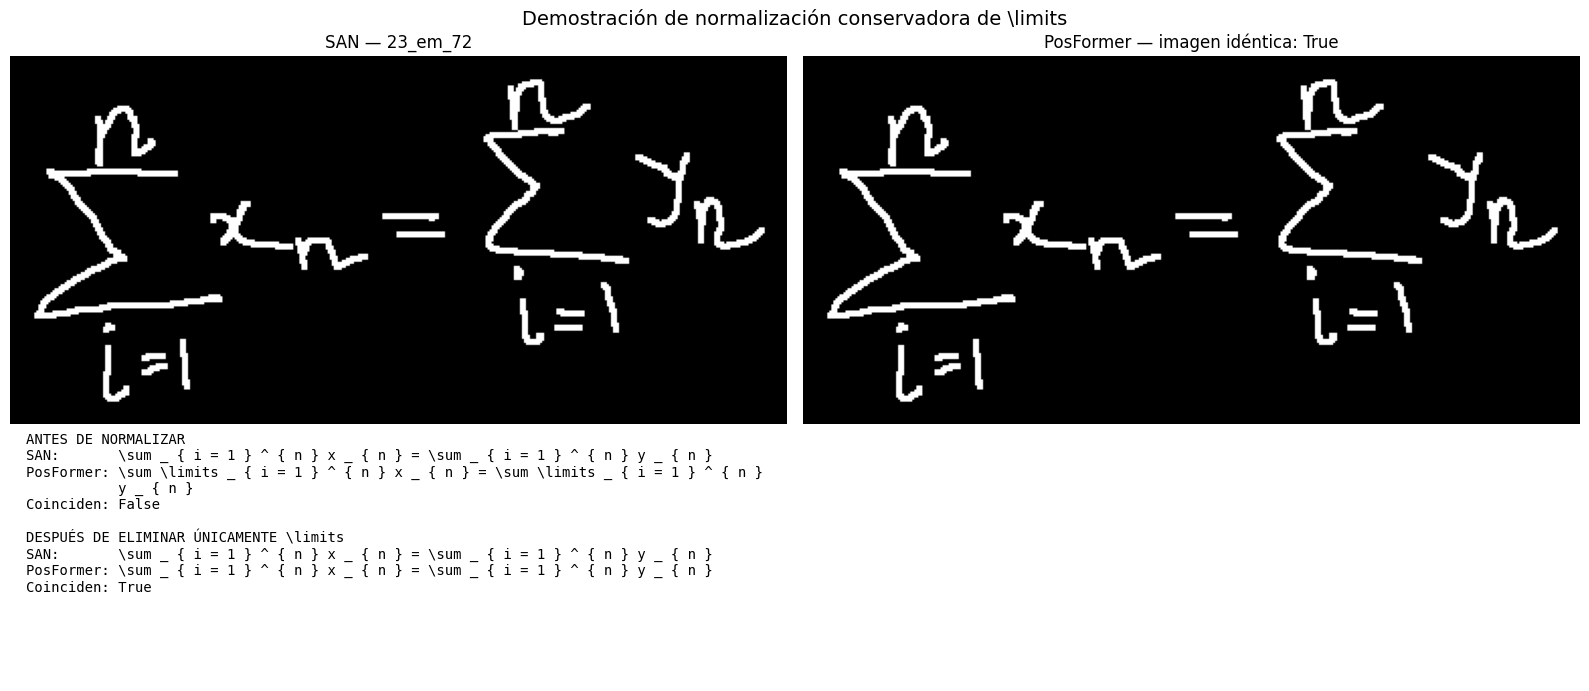

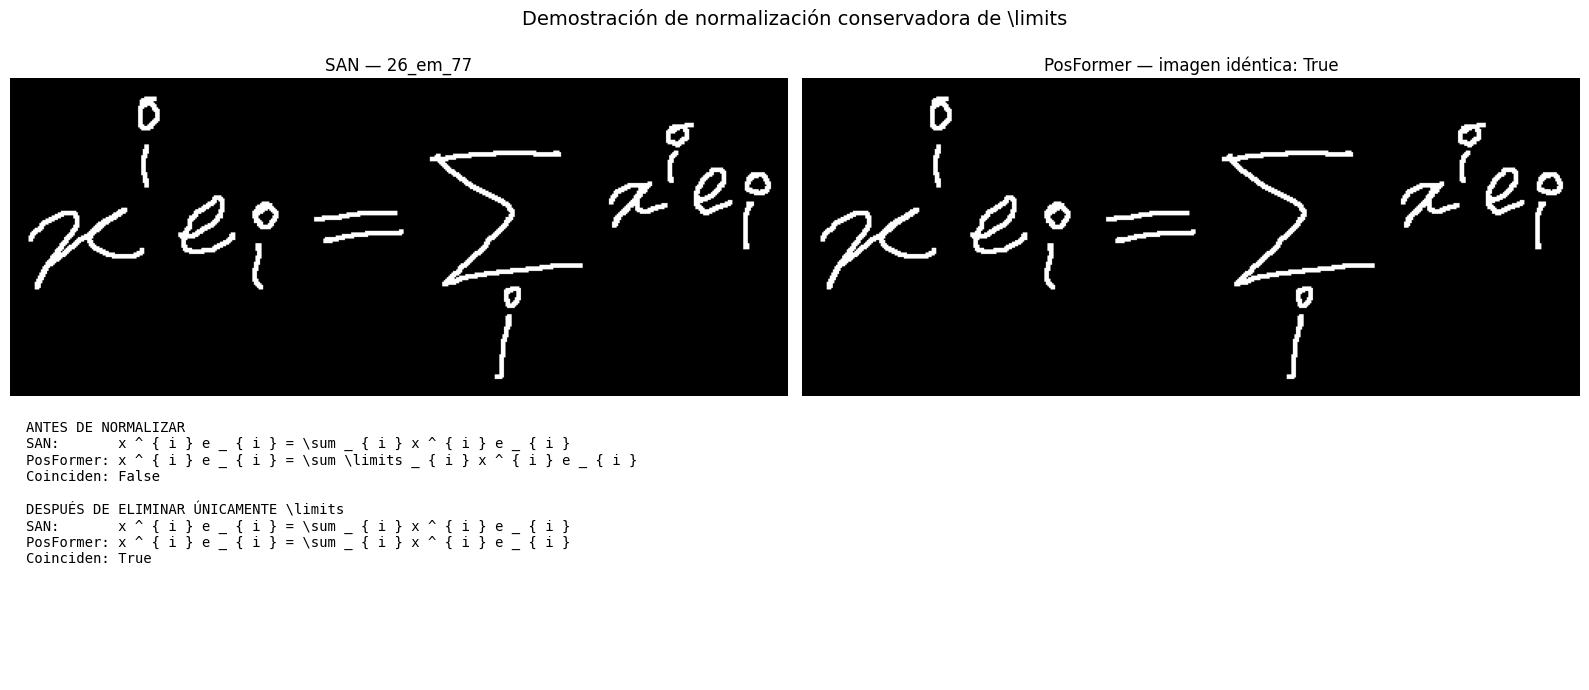

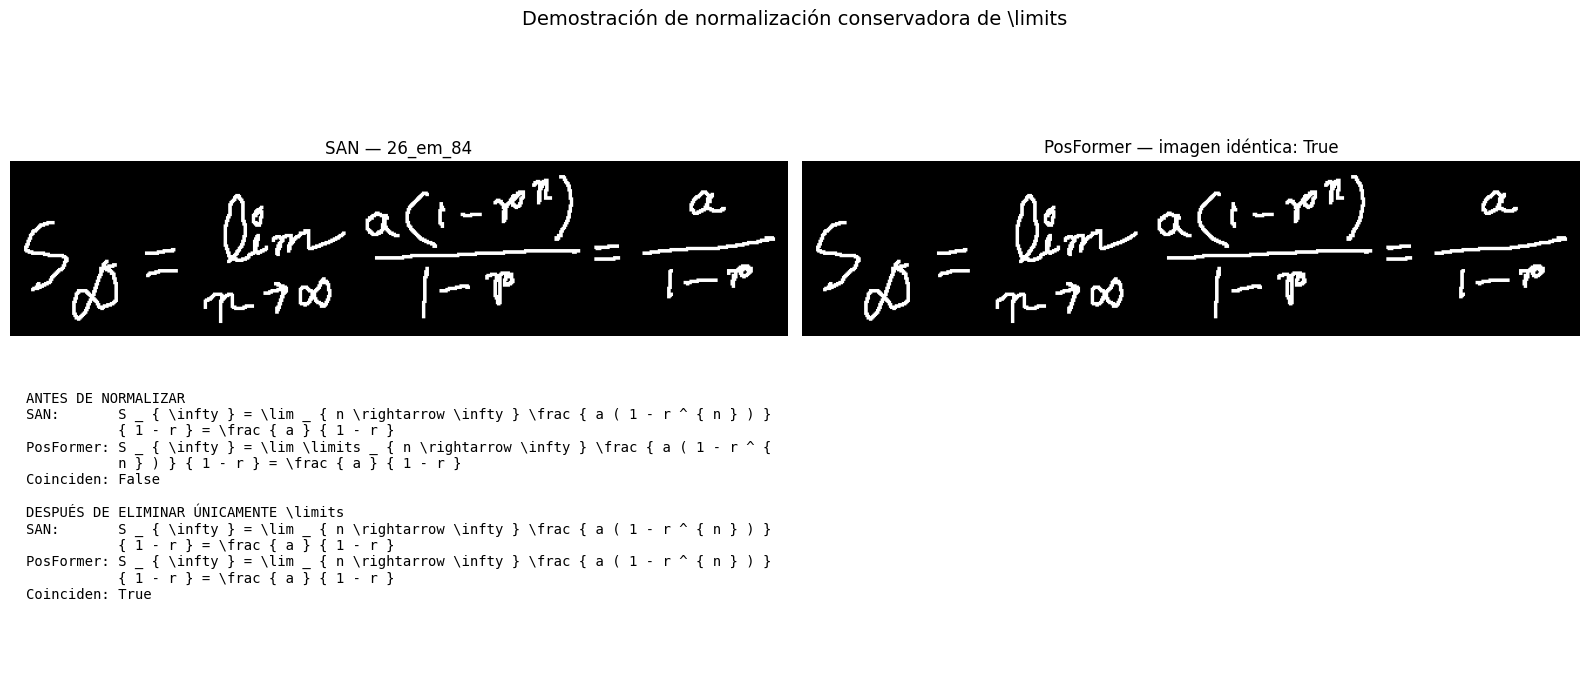

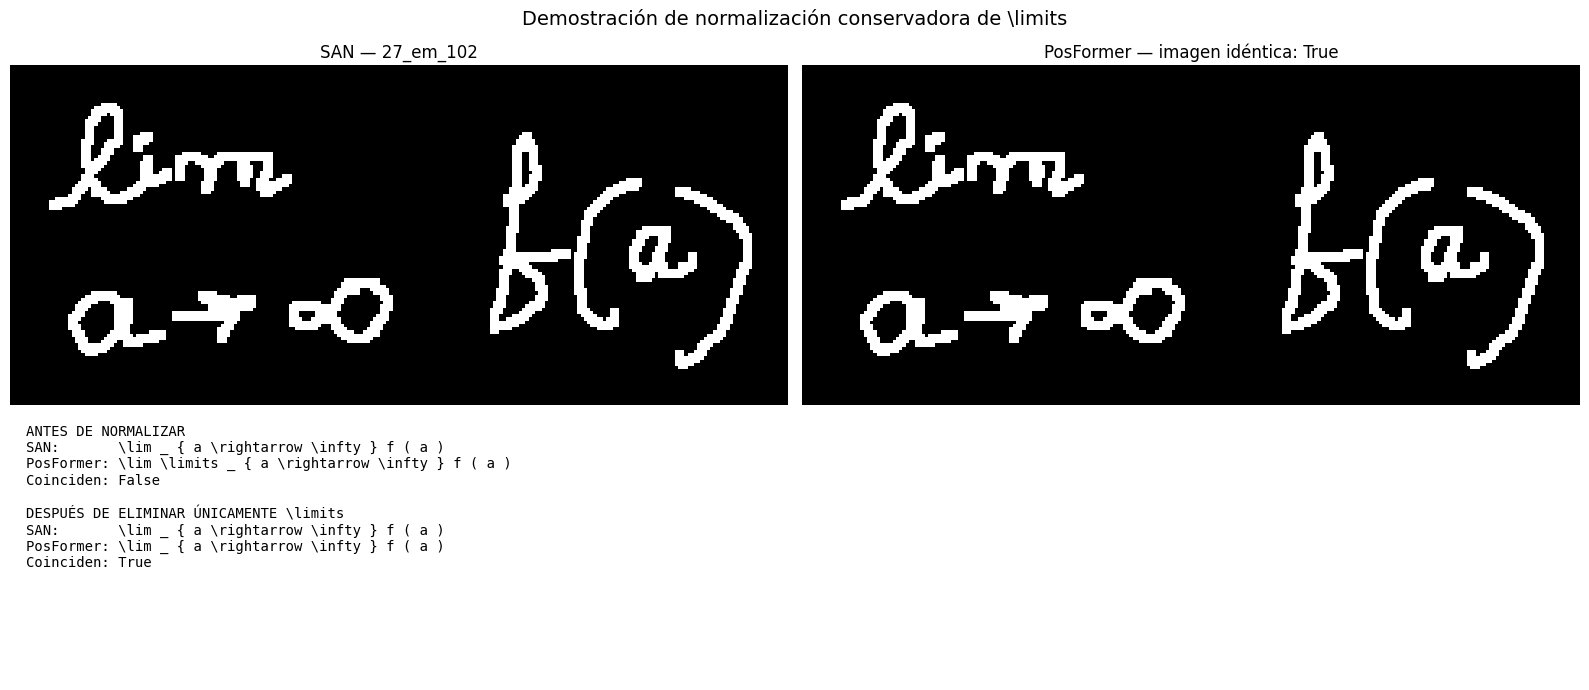

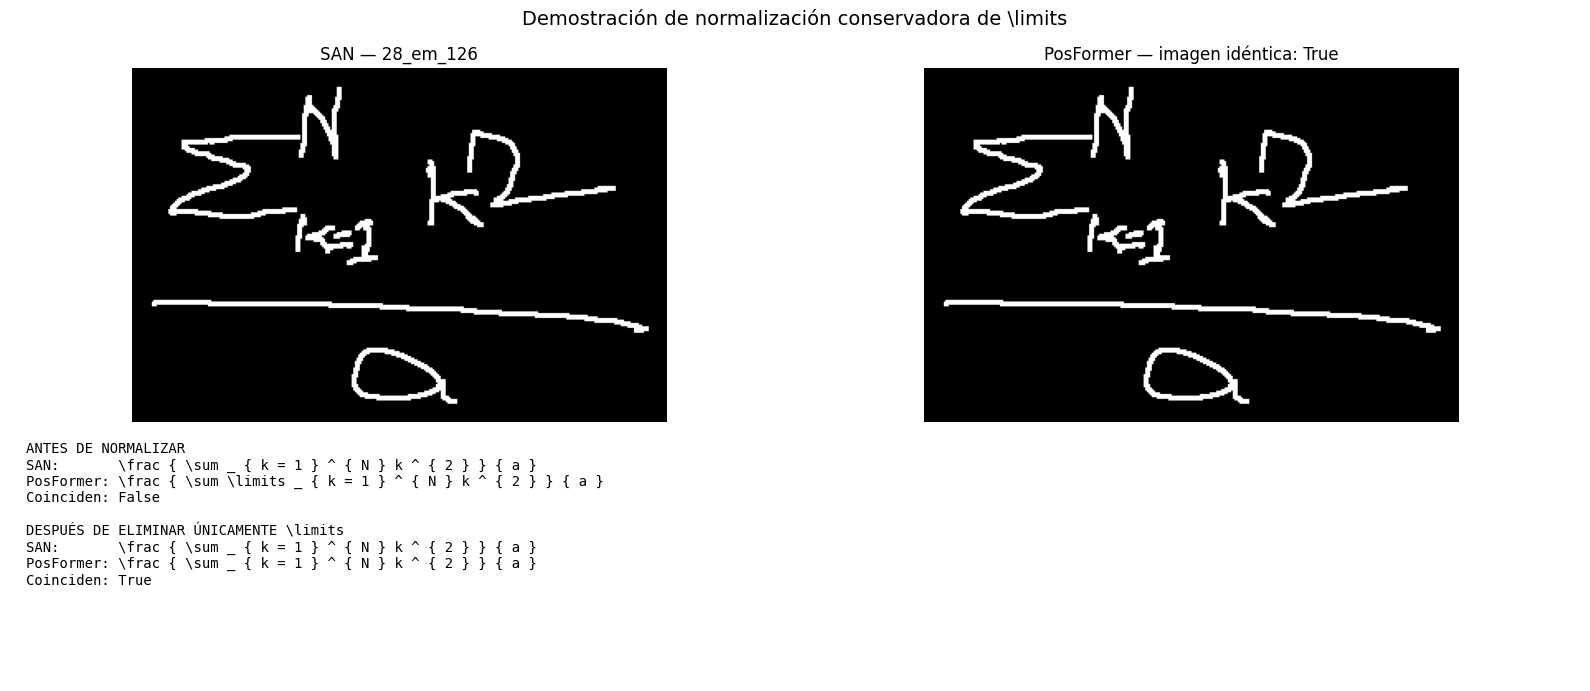

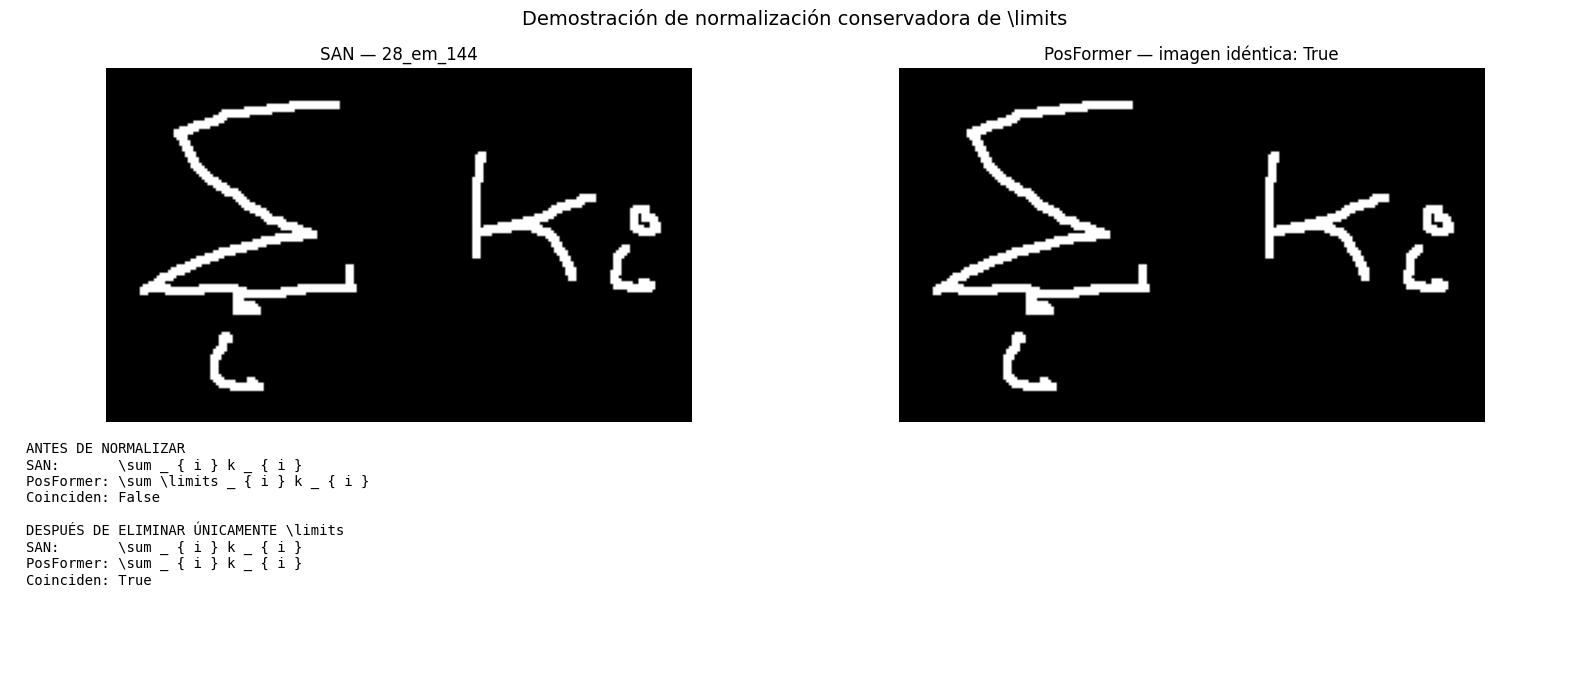

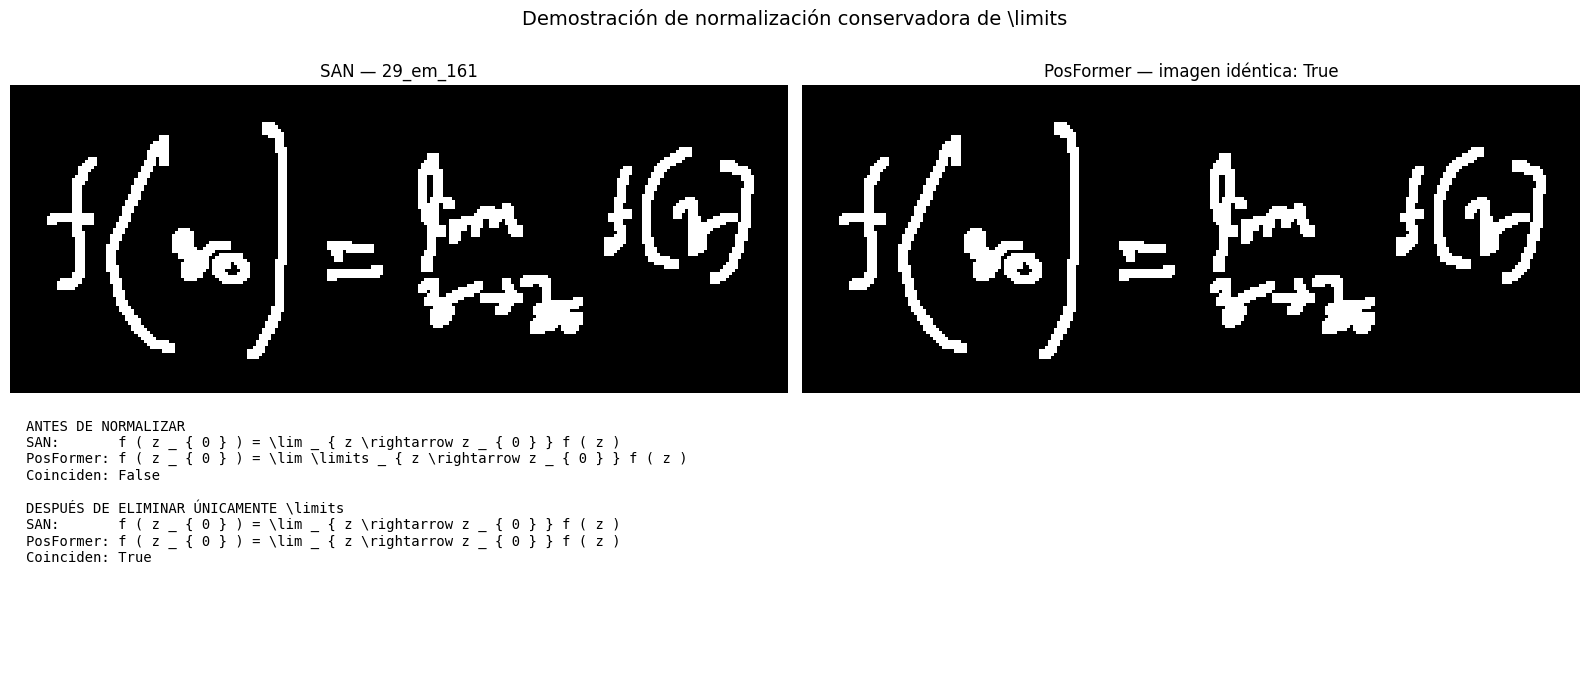

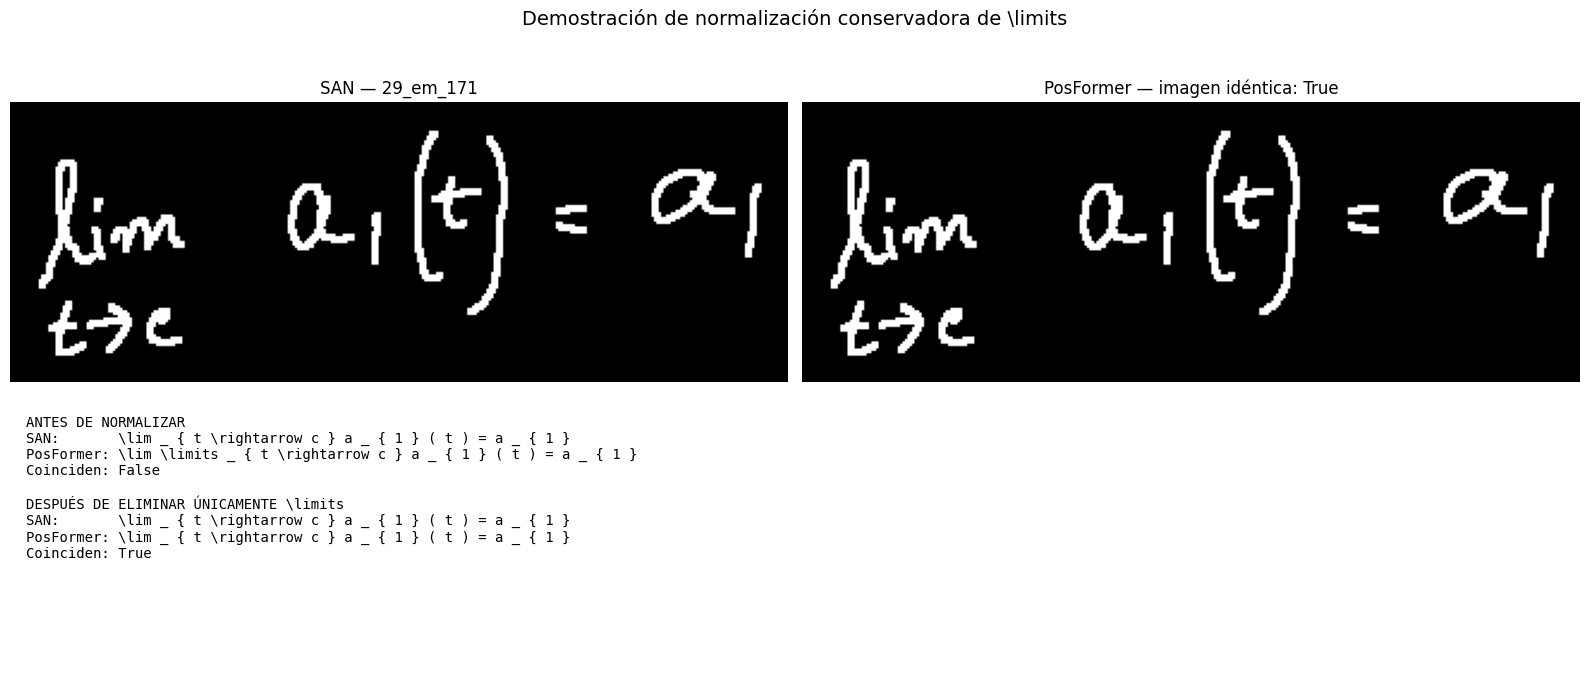

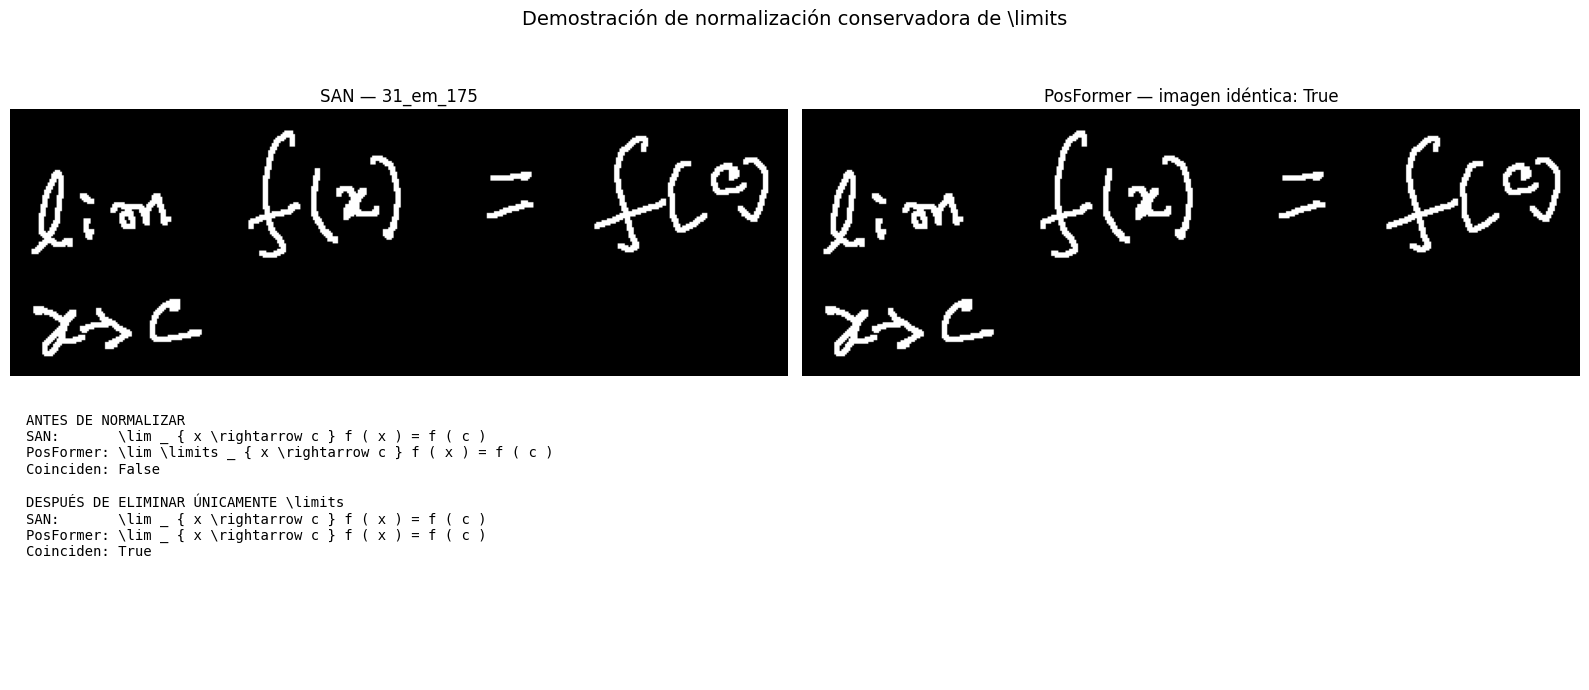

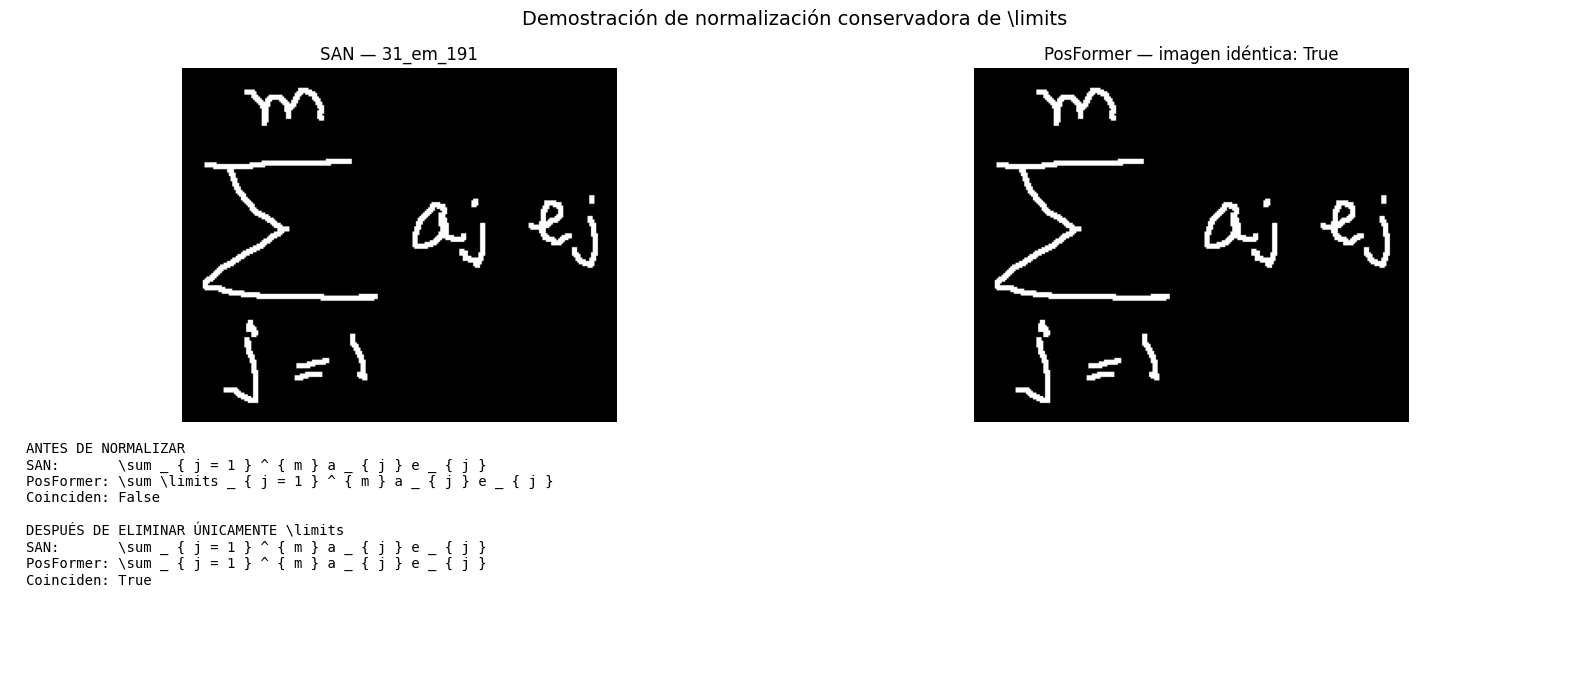

In [14]:
# Dibuja un caso con ambas imágenes y las anotaciones antes/después.
def mostrar_caso_antes_despues(fila):
    identificador = fila["id"]

    with Image.open(fila["ruta_imagen_san"]) as imagen:
        imagen_san = np.asarray(imagen.convert("L"))
    with Image.open(fila["ruta_imagen_posformer"]) as imagen:
        imagen_posformer = np.asarray(imagen.convert("L"))

    figura = plt.figure(figsize=(16, 7))
    rejilla = figura.add_gridspec(2, 2, height_ratios=[3.2, 2.2])

    eje_san = figura.add_subplot(rejilla[0, 0])
    eje_posformer = figura.add_subplot(rejilla[0, 1])
    eje_texto = figura.add_subplot(rejilla[1, :])

    eje_san.imshow(imagen_san, cmap="gray", vmin=0, vmax=255)
    eje_san.set_title(f"SAN — {identificador}")
    eje_san.axis("off")

    eje_posformer.imshow(imagen_posformer, cmap="gray", vmin=0, vmax=255)
    eje_posformer.set_title(
        f"PosFormer — imagen idéntica: {bool(fila['imagenes_identicas'])}"
    )
    eje_posformer.axis("off")

    lineas = [
        "ANTES DE NORMALIZAR",
        "SAN:       " + textwrap.fill(
            fila["ground_truth_san"],
            width=ANCHO_TEXTO,
            subsequent_indent="           ",
        ),
        "PosFormer: " + textwrap.fill(
            fila["ground_truth_posformer"],
            width=ANCHO_TEXTO,
            subsequent_indent="           ",
        ),
        f"Coinciden: {bool(fila['iguales_antes'])}",
        "",
        r"DESPUÉS DE ELIMINAR ÚNICAMENTE \limits",
        "SAN:       " + textwrap.fill(
            fila["ground_truth_san_normalizado"],
            width=ANCHO_TEXTO,
            subsequent_indent="           ",
        ),
        "PosFormer: " + textwrap.fill(
            fila["ground_truth_posformer_normalizado"],
            width=ANCHO_TEXTO,
            subsequent_indent="           ",
        ),
        f"Coinciden: {bool(fila['iguales_despues'])}",
    ]

    eje_texto.axis("off")
    eje_texto.text(
        0.01,
        0.98,
        "\n".join(lineas),
        va="top",
        ha="left",
        family="monospace",
        fontsize=10,
    )

    figura.suptitle(
        r"Demostración de normalización conservadora de \limits",
        fontsize=14,
    )
    figura.tight_layout()
    plt.show()

# Selecciona un subconjunto manejable o todos los casos si el límite es None.
if MAX_CASOS_DEMOSTRACION is None:
    casos_demostracion = casos_solo_limits
else:
    casos_demostracion = casos_solo_limits.head(MAX_CASOS_DEMOSTRACION)

print(
    f"Se mostrarán {len(casos_demostracion)} de "
    f"{len(casos_solo_limits)} casos explicados solo por \\limits."
)

for _, caso in casos_demostracion.iterrows():
    mostrar_caso_antes_despues(caso)

## 8. Selección manual de identificadores

Esta celda permite inspeccionar cualquier conjunto concreto de IDs sin cambiar la clasificación ni los datos.

In [15]:
# Escriba aquí IDs concretos si desea revisar muestras adicionales.
IDS_A_REVISAR = [
    # "RIT_2014_...",
]

ids_desconocidos = sorted(set(IDS_A_REVISAR) - set(comparacion["id"]))
if ids_desconocidos:
    raise KeyError(f"IDs no encontrados: {ids_desconocidos}")

for identificador in IDS_A_REVISAR:
    fila = comparacion.loc[comparacion["id"] == identificador].iloc[0]
    mostrar_caso_antes_despues(fila)

## 9. Casos no resueltos por retirar `\limits`

Estos pares siguen siendo diferentes después de aplicar la regla. Se muestran para dejar claro el límite de la normalización: no deben corregirse automáticamente ni mezclarse con los casos explicados únicamente por `\limits`.

Casos no resueltos por retirar \limits: 6


,id,ground_truth_san,ground_truth_posformer,ground_truth_san_normalizado,ground_truth_posformer_normalizado
710,RIT_2014_133,0 \leq x \leq 2 \pi,0 \leq x \leq 2 \Pi,0 \leq x \leq 2 \pi,0 \leq x \leq 2 \Pi
774,RIT_2014_191,x [ \infty ] = \lim _ { z \rightarrow 1 ( z - 1 ) x ( z ) },x [ \infty ] = \lim \limits _ { z \rightarrow 1 } ( z - 1 ) x ( z ),x [ \infty ] = \lim _ { z \rightarrow 1 ( z - 1 ) x ( z ) },x [ \infty ] = \lim _ { z \rightarrow 1 } ( z - 1 ) x ( z )
802,RIT_2014_216,\lim _ { y \rightarrow x f ( y ) = f ( x ) },\lim \limits _ { y \rightarrow x } f ( y ) = f ( x ),\lim _ { y \rightarrow x f ( y ) = f ( x ) },\lim _ { y \rightarrow x } f ( y ) = f ( x )
803,RIT_2014_217,"v _ { \pm 1 , \pm 2 _ { , } \pm 3 }","v _ { \pm 1 , \pm 2 , \pm 3 }","v _ { \pm 1 , \pm 2 _ { , } \pm 3 }","v _ { \pm 1 , \pm 2 , \pm 3 }"
812,RIT_2014_225,"d ( x , y ) + d ( y _ { , } z ) \geq d ( x _ { , } z )","d ( x , y ) + d ( y , z ) \geq d ( x , z )","d ( x , y ) + d ( y _ { , } z ) \geq d ( x _ { , } z )","d ( x , y ) + d ( y , z ) \geq d ( x , z )"
932,RIT_2014_51,"1 , 0 0 0 _ { , } 0 0 0 _ { , } 0 0 0","1 , 0 0 0 , 0 0 0 , 0 0 0","1 , 0 0 0 _ { , } 0 0 0 _ { , } 0 0 0","1 , 0 0 0 , 0 0 0 , 0 0 0"


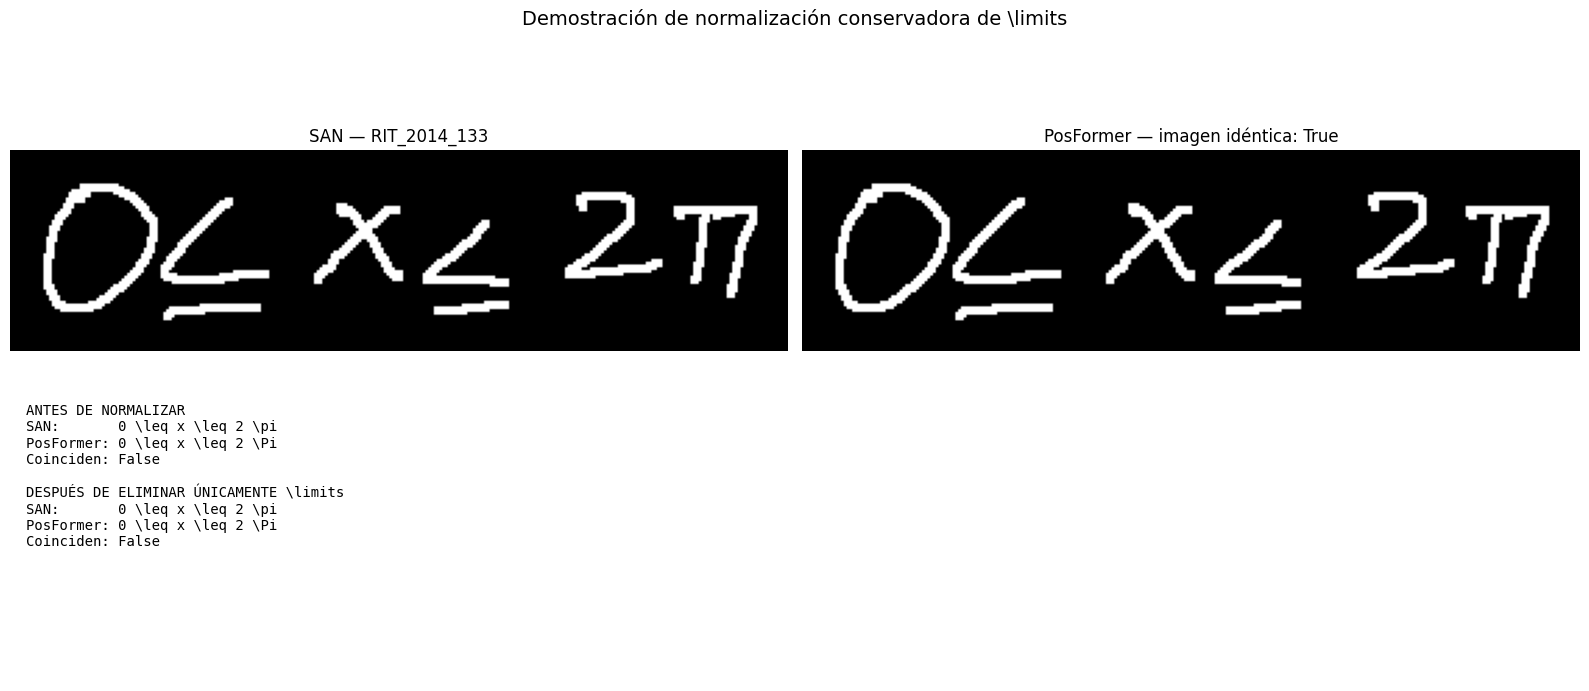

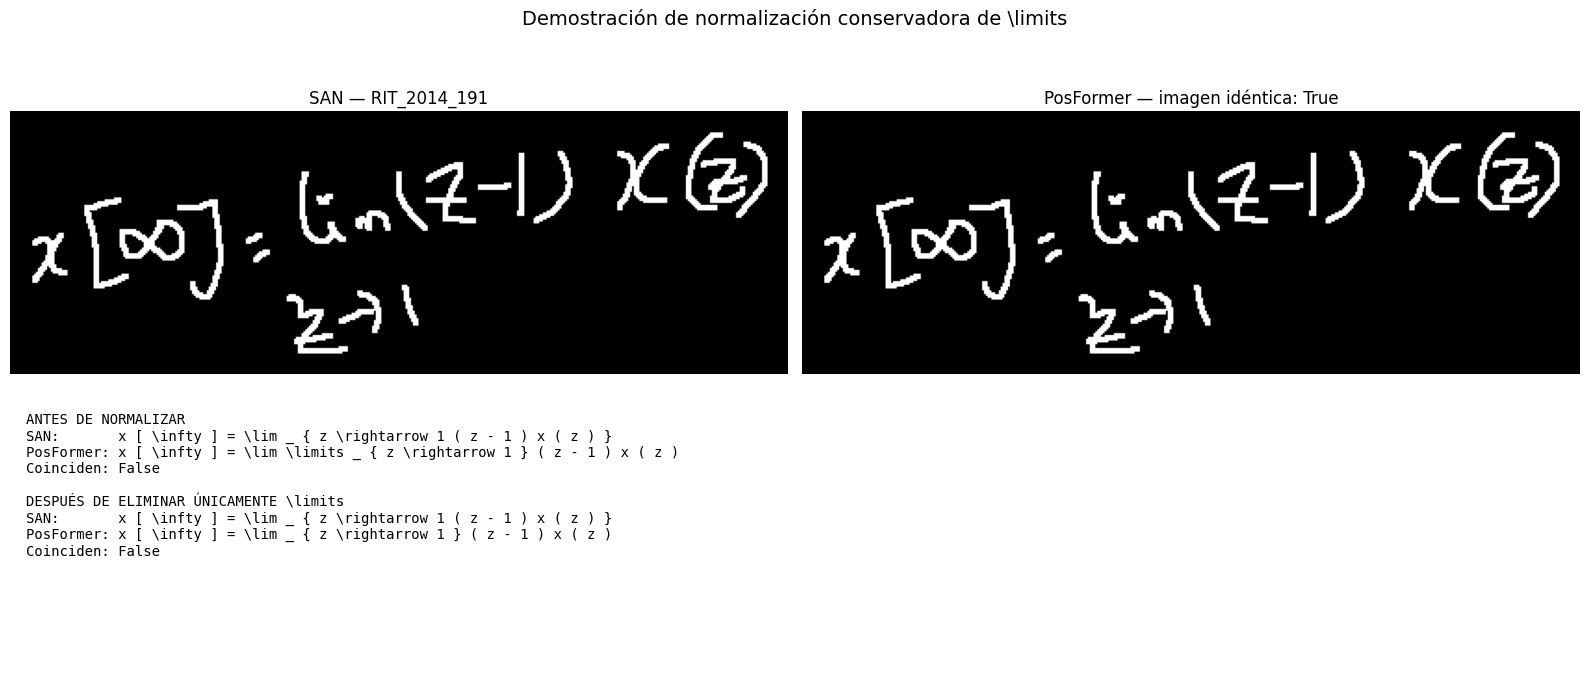

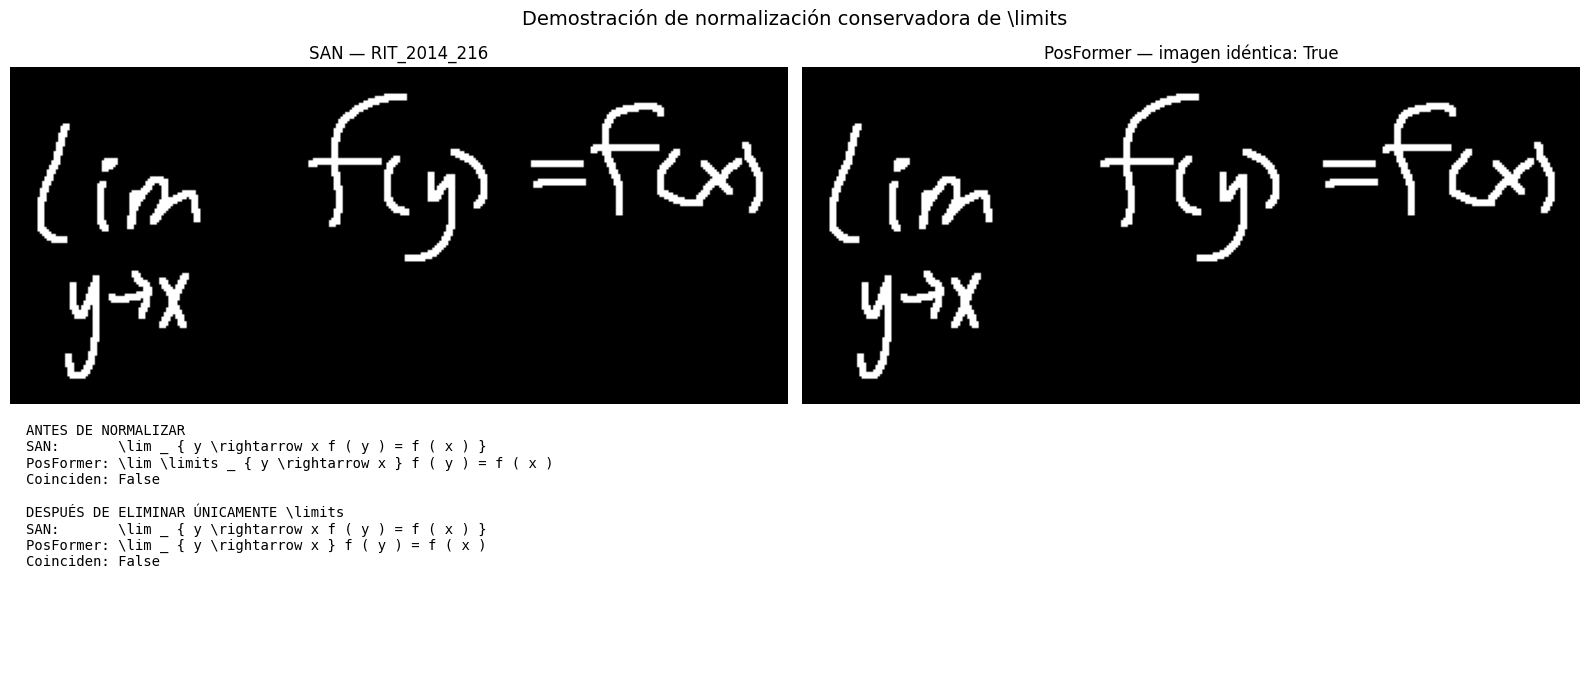

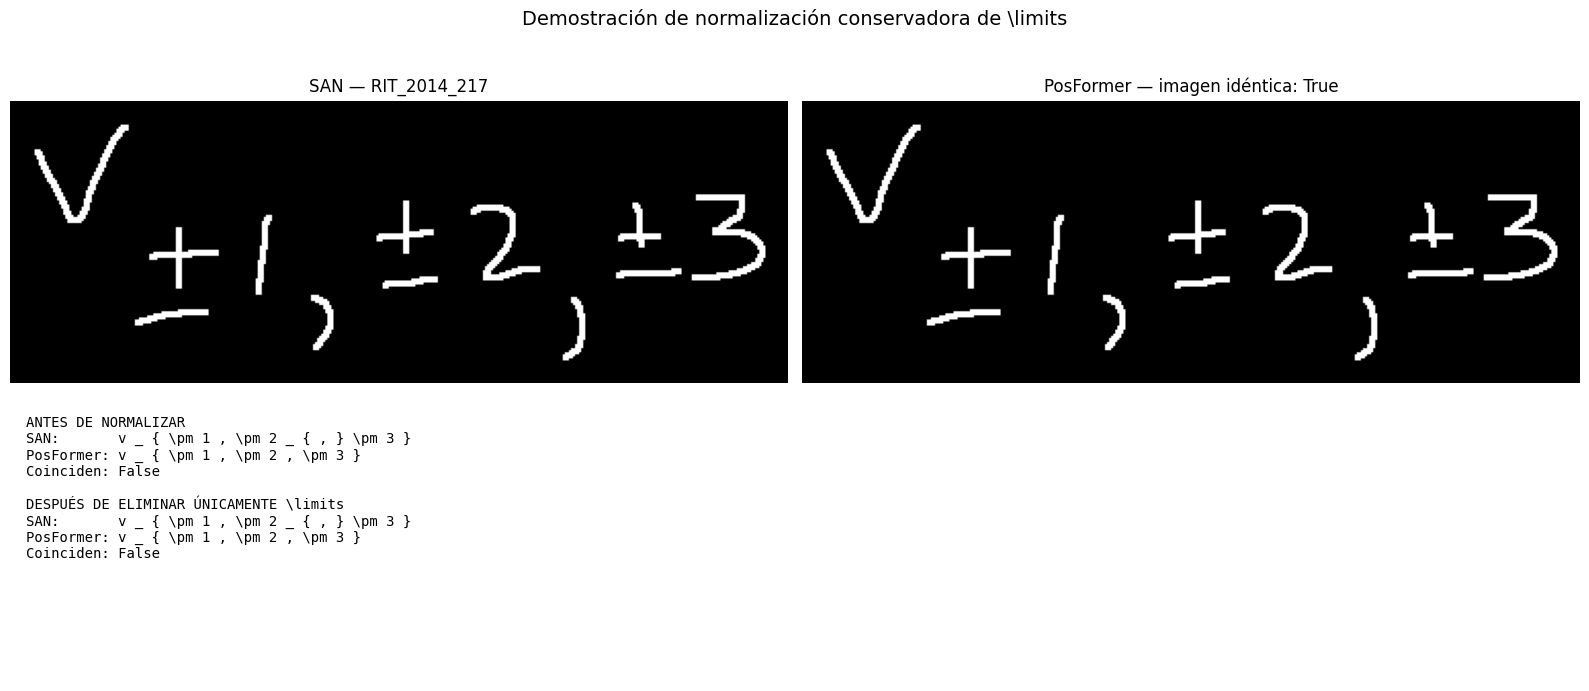

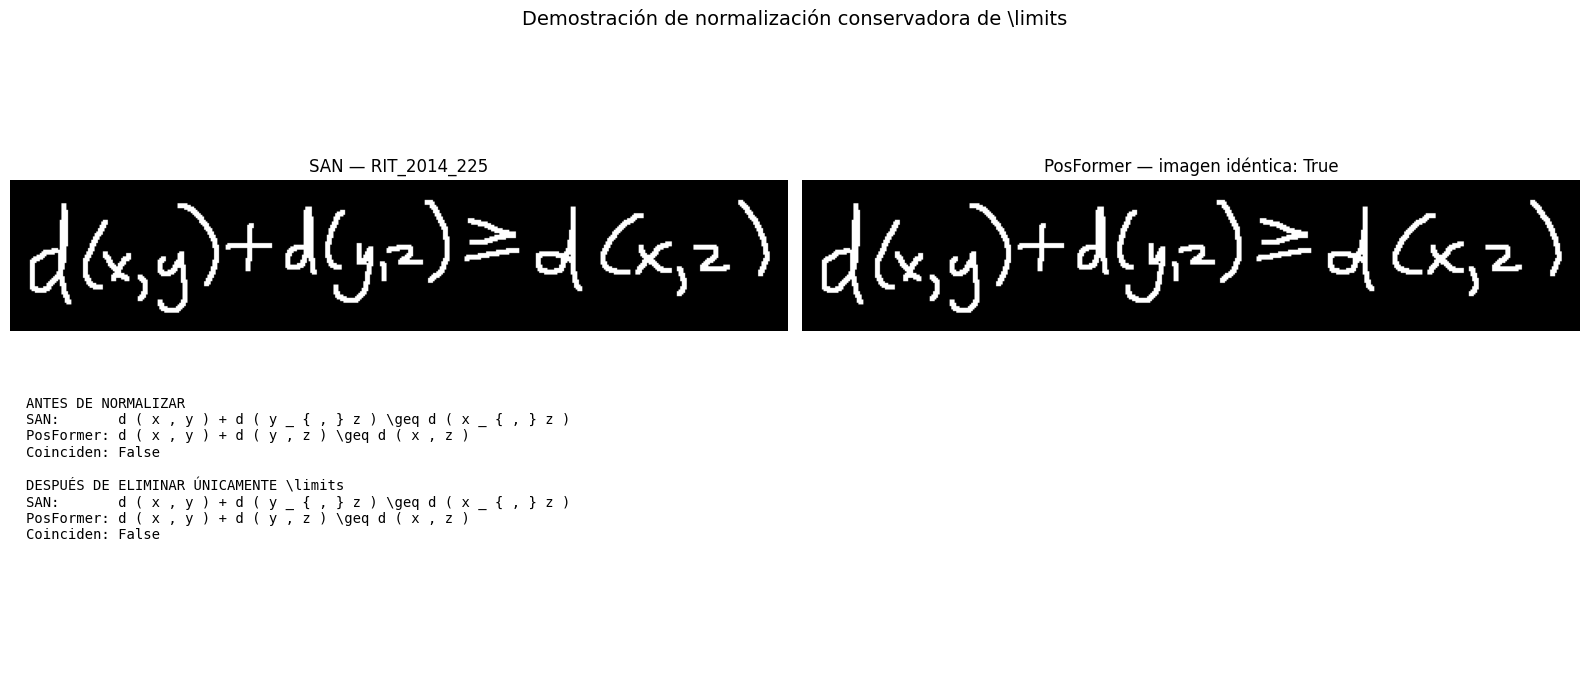

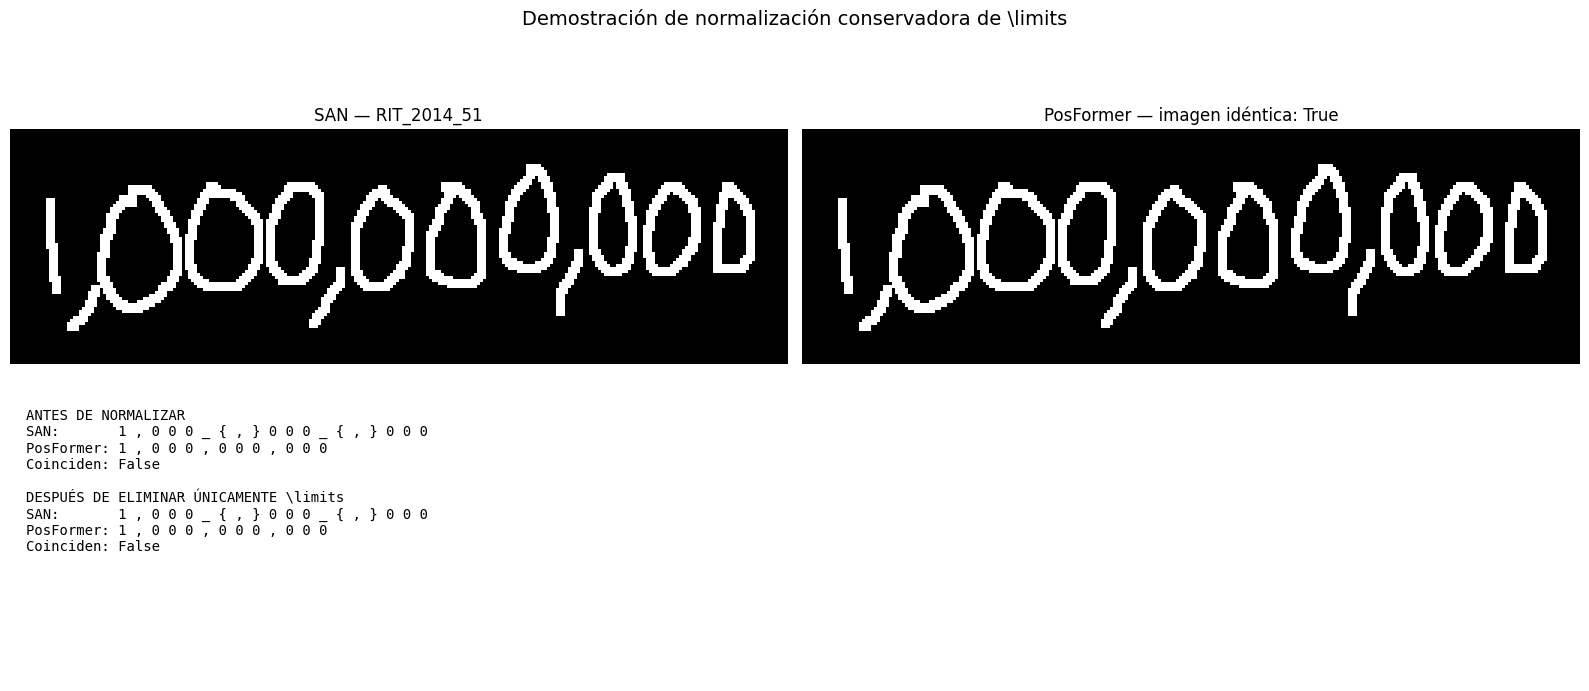

In [16]:
# Aísla las diferencias que requieren revisión visual o adjudicación por ID.
casos_no_resueltos = comparacion.loc[
    ~comparacion["iguales_despues"],
    [
        "id",
        "ground_truth_san",
        "ground_truth_posformer",
        "ground_truth_san_normalizado",
        "ground_truth_posformer_normalizado",
        "imagenes_identicas",
        "ruta_imagen_san",
        "ruta_imagen_posformer",
        "iguales_antes",
        "iguales_despues",
    ],
].sort_values("id")

print(f"Casos no resueltos por retirar \\limits: {len(casos_no_resueltos)}")
display(
    casos_no_resueltos[
        [
            "id",
            "ground_truth_san",
            "ground_truth_posformer",
            "ground_truth_san_normalizado",
            "ground_truth_posformer_normalizado",
        ]
    ]
)

# La visualización reutiliza el mismo formato, pero no decide cuál anotación es correcta.
for _, caso in casos_no_resueltos.iterrows():
    mostrar_caso_antes_despues(caso)

## 10. Comprobaciones de invariantes

Estas aserciones verifican que la normalización no introdujo tokens, no alteró el orden de los tokens restantes y no modificó las columnas originales.

In [17]:
# Verifica formalmente que la salida equivale a filtrar solo el token \limits.
def tokens_sin_limits(secuencia):
    return [token for token in str(secuencia).split() if token != r"\limits"]

for prefijo in ["san", "posformer"]:
    original = comparacion[f"ground_truth_{prefijo}"]
    normalizado = comparacion[f"ground_truth_{prefijo}_normalizado"]

    assert all(
        salida.split() == tokens_sin_limits(entrada)
        for entrada, salida in zip(original, normalizado)
    )
    assert not normalizado.map(lambda texto: r"\limits" in texto.split()).any()

print("Comprobaciones superadas: solo se elimina el token exacto \\limits.")

Comprobaciones superadas: solo se elimina el token exacto \limits.


## Interpretación

- Si un par era diferente antes y coincide después, la discrepancia queda explicada por la presencia de `\limits`.
- Las imágenes se presentan por separado para conservar la trazabilidad de cada distribución, aunque el EDA previo mostró que los BMP correspondientes son idénticos.
- Los casos que continúan diferentes no validan nuevas reglas automáticas. Comas, llaves y diferencias de símbolos deben revisarse individualmente.
- La normalización sirve únicamente para comparar referencias y predicciones. No debe usarse para calcular confianza ni para decidir la derivación de la cascada.
- Los archivos originales permanecen sin cambios y la métrica estricta debe conservarse junto con la métrica normalizada.